# Comparison: `fastpiclef` vs the reference codes

A reproducible, single-machine comparison of the wave-optics Fresnel-integral solvers in `refs/`
against `fastpiclef`. This notebook **runs the harness live** and compiles all results.

The reference codes are compared one at a time, each in the protocol it is built for — so the
notebook is organised **by reference code**:

| part | reference code | kind | protocol |
|---|---|---|---|
| **A** | [`plind`](https://pypi.org/project/plind/) | Python, PL flow | single source position at a time |
| **B** | `P-LPI` (`refs/P-LPI`) | C++, PL flow | a whole grid of source positions at once |

**Shared test case.** Both parts exercise the *same* lens family — `RationalLens(kappa=-2)`,
$\phi=(x-\mu)^2/2 + 2/(1+x^2)$, at $\omega=\nu=10$ (P-LPI's hardcoded benchmark). Part A hits it at a
single source position (alongside two other cases); Part B sweeps its source position into a full
512-point grid. So `plind` is graded on it single-point **and** on the grid, giving a common thread
through both parts.

**Method & fairness**
* Compared quantity: the raw integral $\int e^{i\omega\phi}\,dx$ (convention-free; the amplification
  $F$ is a fixed rescaling of it).
* **Truth**: our machine-precision *thimble* result, independently validated — it agrees with a
  method-independent brute-force referee (raw-integrand quadrature + exact Fresnel tails) to that
  referee's ~$10^{-6}$ floor, and with the exact Airy function to $3\times10^{-15}$. Grading an
  *independent* code against it is fair.
* **Single-threaded** (`RAYON_NUM_THREADS = OMP_NUM_THREADS = 1`); threaded speed is a separate axis.

*Run in the env that has both Jupyter and the reference codes:* `pixi run -e notebook lab`, or
headless via `pixi run notebook-comparison`.

In [1]:
import os, sys
root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(root, 'pyproject.toml')) and root != '/':
    root = os.path.dirname(root)
sys.path.insert(0, root); os.chdir(root)

import comparison.run as H          # sets single-thread pin, then imports fastpiclef
import comparison.cases as C
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
print('repo root :', root)
print('threads   : RAYON =', os.environ.get('RAYON_NUM_THREADS'), ' OMP =', os.environ.get('OMP_NUM_THREADS'))
print('cases     :', [c.name for c in C.CASES])

repo root : /home/paul/Dropbox/CUHK/01-Picard-Lefschetz_and_lensing/Fast_Picard-Lefshetz_integral_code
threads   : RAYON = 1  OMP = 1
cases     : ['rational b=0.3 k=-2.0 w=10', 'rational b=0.3 k=0.2 w=1', 'airy y=1.0 w=1']


## Part A — versus `plind` (Python PL flow · single-point protocol)

`plind` solves one source position per call. We compare on three cases: the shared
`RationalLens(k=-2, w=10)` (strong, multi-image — P-LPI's lens), a gentle diverging lens, and the
Airy (cubic) phase whose exact value anchors the accuracy scale.

### A.1 — Reference sanity: is our 'truth' trustworthy?

Our thimble truth vs the independent brute-force referee. They agree down to the referee's own
~$10^{-6}$ floor (its analytic tail neglects the potential's tail), which is why it is used only as a
cross-check, not to grade sub-$10^{-6}$ solvers. (For Airy the truth *is* the exact Airy function.)

In [2]:
san = pd.DataFrame(
    [(c.name, H.rel(c.truth, c.referee)) for c in C.CASES],
    columns=['case', 'thimble vs brute-force referee (rel.)'])
(san.style.format({'thimble vs brute-force referee (rel.)': '{:.1e}'})
    .hide(axis='index')
    .set_caption('A.1 — Truth cross-check: thimble vs independent referee'))

case,thimble vs brute-force referee (rel.)
rational b=0.3 k=-2.0 w=10,3.3e-05
rational b=0.3 k=0.2 w=1,2.2e-06
airy y=1.0 w=1,0.0e+00


### A.2 — Accuracy & speed (single-threaded)

Relative error (vs the validated truth) and median wall time over repetitions, across the three
cases. The first, `rational b=0.3 k=-2 w=10`, **is** P-LPI's lens at a single source position —
Part B sweeps it into a grid.

In [3]:
df = H.summary_table()            # runs fastpiclef (thimble+mesh) and plind on each case
tbl = df.rename(columns={'solver': 'method', 'rel_err': 'relative error'})
tbl['wall time (ms)'] = tbl['time_s'] * 1e3
(tbl[['case', 'method', 'relative error', 'wall time (ms)']]
    .style.format({'relative error': '{:.2e}', 'wall time (ms)': '{:.2f}'})
    .hide(axis='index')
    .set_caption('A.2 — Accuracy (rel. error vs validated truth) and single-thread wall time'))

/home/paul/Dropbox/CUHK/01-Picard-Lefschetz_and_lensing/Fast_Picard-Lefshetz_integral_code/.pixi/envs/notebook/lib/python3.14/site-packages/plind/descend/core.py:34: RuntimeWarning: divide by zero encountered in divide
  delta = np.min((np.divide(tol, 2*R))**(1/4))


total steps: 3640 current time: 1.501111699704961


total steps: 3640 current time: 1.501111699704961


total steps: 3640 current time: 1.501111699704961


total steps: 3640 current time: 1.501111699704961
total steps: 12 current time: 1.5658250587466271


total steps: 12 current time: 1.5658250587466271
total steps: 12 current time: 1.5658250587466271


... (2 outputs left out)

total steps: 91 current time: 1.5137474099313217


total steps: 91 current time: 1.5137474099313217


total steps: 91 current time: 1.5137474099313217


case,method,relative error,wall time (ms)
rational b=0.3 k=-2.0 w=10,fastpiclef/auto,0.00e+00,0.75
rational b=0.3 k=-2.0 w=10,fastpiclef/mesh,7.22e-15,7.11
rational b=0.3 k=-2.0 w=10,plind,6.64e-03,2457.70
rational b=0.3 k=0.2 w=1,fastpiclef/auto,0.00e+00,0.32
rational b=0.3 k=0.2 w=1,fastpiclef/mesh,1.68e-13,10.53
rational b=0.3 k=0.2 w=1,plind,2.95e-10,119.45
airy y=1.0 w=1,fastpiclef/auto,2.90e-15,0.23
airy y=1.0 w=1,fastpiclef/mesh,6.60e-16,4.02
airy y=1.0 w=1,plind,2.12e-07,486.86


#### Headline: `fastpiclef` (auto) vs `plind`

In [4]:
piv = df.pivot_table(index='case', columns='solver', values='time_s')
head = pd.DataFrame({
    'plind time (s)': piv['plind'],
    'fastpiclef time (ms)': piv['fastpiclef/auto'] * 1e3,
    'speedup': piv['plind'] / piv['fastpiclef/auto'],
})
(head.style.format({'plind time (s)': '{:.3f}', 'fastpiclef time (ms)': '{:.2f}', 'speedup': '{:.0f}x'})
    .set_caption('Headline: single-point speedup, fastpiclef (auto) vs plind'))

,plind time (s),fastpiclef time (ms),speedup
case,,,
airy y=1.0 w=1,0.487,0.23,2139x
rational b=0.3 k=-2.0 w=10,2.458,0.75,3276x
rational b=0.3 k=0.2 w=1,0.119,0.32,373x


### A.3 — The real differentiator: error vs cost

How accuracy scales with wall time (the resolution knob is swept for each flow method). `fastpiclef`
sits at the bottom-left (fast **and** machine-precise — the adaptive stopping means the mesh does not
trade accuracy for cost); `plind` at the top-right. The thimble ★ is the reference (fastest, exact).

total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.5438924996038508
total steps: 32 current time: 1.5438924996038508


total steps: 32 current time: 1.539269997668487
total steps: 32 current time: 1.539269997668487


total steps: 32 current time: 1.539269997668487
total steps: 32 current time: 1.539269997668487


total steps: 32 current time: 1.5382943964986286
total steps: 32 current time: 1.5382943964986286


total steps: 32 current time: 1.5382943964986286
total steps: 32 current time: 1.5382943964986286


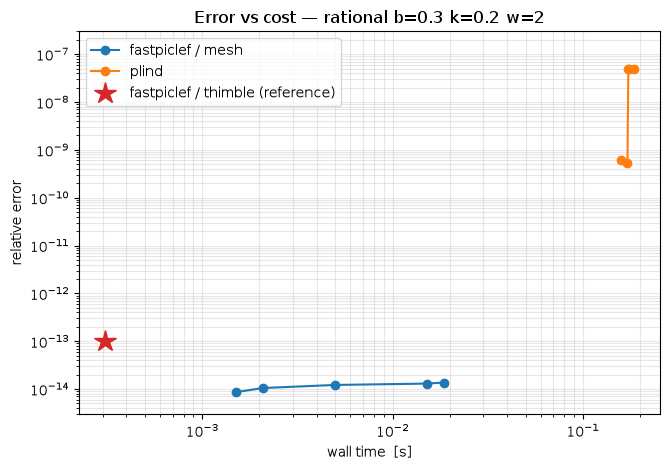

In [5]:
case, series, thimble_pt = H.convergence_curve()
fig, ax = plt.subplots(figsize=(6.8, 4.8))
H.plot_convergence(ax, case, series, thimble_pt)
plt.tight_layout(); plt.show()

## Part B — versus `P-LPI` (C++ PL flow · grid protocol)

`P-LPI` (`refs/P-LPI/code_1D`) natively computes a whole *grid* of source positions at once. Its
hardcoded case is exactly the shared lens — `RationalLens(kappa=-2)` at $\nu=10$ — over
$\mu\in[-4,4]$ (512 points). This gives a **third independent PL cross-check** (from a code we did
not write) and the natural setting for the *grid* protocol. It amortises by reusing 32 thimbles
across the 512 points (a built-in warm-start).

All three codes run the **same grid** here: `fastpiclef` (512 independent solves), `P-LPI` (batched),
and `plind` (subsampled — it is ~1 s/point). So `plind`, tested single-point in Part A, is re-tested
on the grid here — the shared lens tying the two parts together. Below: $|F(\mu)|$ from all three
(they overlay — the 3-way agreement), then each code's accuracy across the grid vs the fastpiclef
thimble reference.

/home/paul/Dropbox/CUHK/01-Picard-Lefschetz_and_lensing/Fast_Picard-Lefshetz_integral_code/.pixi/envs/notebook/lib/python3.14/site-packages/plind/descend/core.py:34: RuntimeWarning: divide by zero encountered in divide
  delta = np.min((np.divide(tol, 2*R))**(1/4))


total steps: 217 current time: 1.5094399028579584


total steps: 259 current time: 1.5045485142936434


total steps: 325 current time: 1.5040719615227194


total steps: 504 current time: 1.5022236892905385


total steps: 2952 current time: 1.5003858771374787


... (6 outputs left out)

total steps: 742 current time: 1.5026244292867499


total steps: 325 current time: 1.5040702993888253


total steps: 267 current time: 1.5104593346792017


total steps: 217 current time: 1.509442333623943


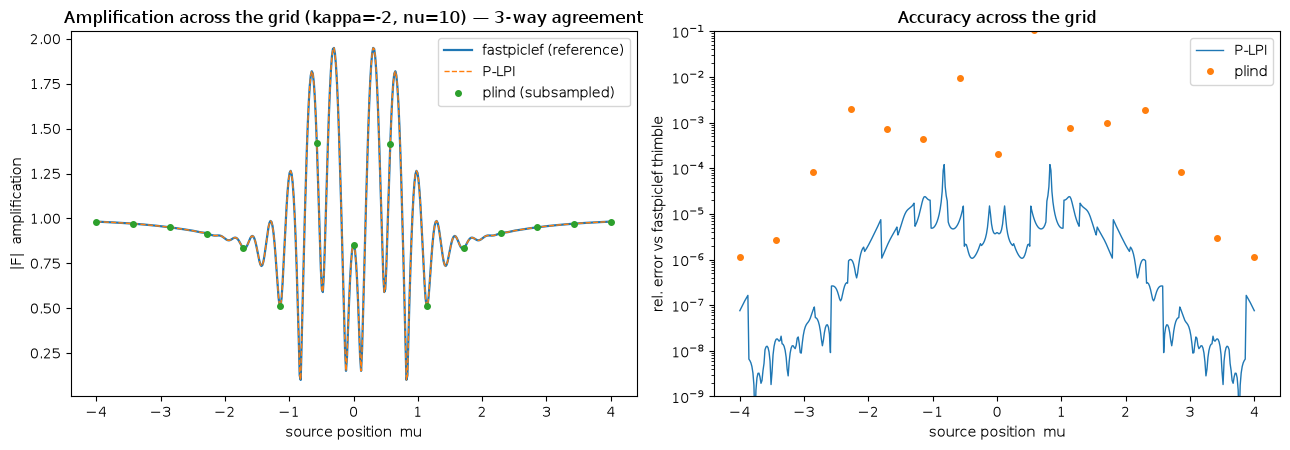

In [6]:
res = H.grid_comparison()   # builds+runs P-LPI, loops fastpiclef, subsamples plind (~30 s)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
H.plot_grid_overlay(a1, res)
H.plot_grid_error(a2, res)
plt.tight_layout(); plt.show()

In [7]:
(pd.DataFrame(res['times'].items(), columns=['configuration', 'wall time (s)'])
    .style.format({'wall time (s)': '{:.3f}'})
    .hide(axis='index')
    .set_caption('B — Grid wall time, 512 source positions (single-thread unless noted)'))

configuration,wall time (s)
"fastpiclef (512, 1 thr)",0.290
"P-LPI (512, 1 thr)",0.182
"P-LPI (512, 12 thr)",0.078
plind/pt,1.461
"plind (512, extrapolated)",747.777


## Interpretation & caveats

**vs `plind` (Part A, single-point).** Across all cases `fastpiclef` is **~300–5000× faster and more
accurate**, single-threaded. Part of the raw speedup is Rust-vs-Python; part is genuinely better
algorithms — the `mesh`-vs-`plind` row isolates the former (same PL-flow method), the `thimble` the
latter. `plind` ran with reasonable-but-not-hand-tuned parameters; the A.3 curve sweeps its
resolution, so the comparison is against its whole error-vs-cost frontier, not one point.

**vs `P-LPI` (Part B, grid).** On the *grid* protocol P-LPI's 32-thimble reuse makes it
single-thread-competitive with fastpiclef on speed (both ~0.2 s / 512 pts) and faster threaded —
while fastpiclef is ~4–6 orders more accurate (both reference codes lose accuracy near the $\mu=0$
caustic). Here fastpiclef does 512 *independent* solves; contour warm-starting (a roadmap item)
would give it the same amortisation. This is the single-point-vs-grid fairness point in action.

**Common caveats.** Single-threaded only (threaded performance — rayon vs OpenMP vs multiprocessing —
is a separate axis). P-LPI compiled with its own `-ffast-math -march=native` (a mild precision
caveat).

### Still to come

* **FIONA** (FFT/NUFHT): on a shared lens (point mass ⇒ the Nakamura–Deguchi closed form as an
  *external* truth, removing any circularity), in its native $(\omega, y)$-grid protocol where an
  FFT method is judged fairly.
* A **P-LPI resolution sweep** (its own error-vs-cost frontier, like A.3) and **2D** comparisons.